<a href="https://colab.research.google.com/github/Chamanpoorani/CHAMAN_LAL_for_NLP_-_Deep_learning_P2_Project_Submission_pat_1_/blob/main/chaman.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cpu
Training images: 6000
Testing images: 1000
Batch shape: torch.Size([128, 1, 28, 28])


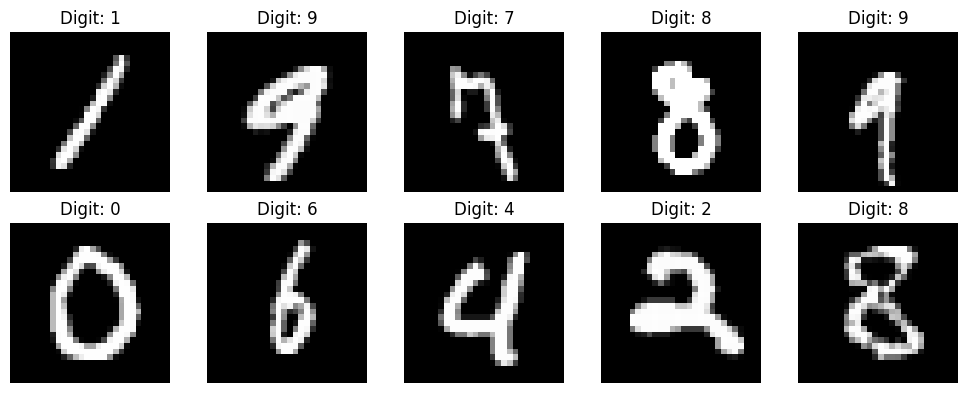

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
  )
  (fc_mu): Linear(in_features=128, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Epoch 1/3 | Train Loss: 327.59 | Recon Loss: 314.87 | KL Loss: 12.72 | Test Loss: 225.88
Epoch 2/3 | Train Loss: 219.06 | Recon Loss: 207.73 | KL Loss: 11.33 | Test Loss: 203.70
Epoch 3/3 | Train Loss: 203.71 | Recon Loss: 194.28 | KL Loss: 9.43 | Test Loss: 194.00


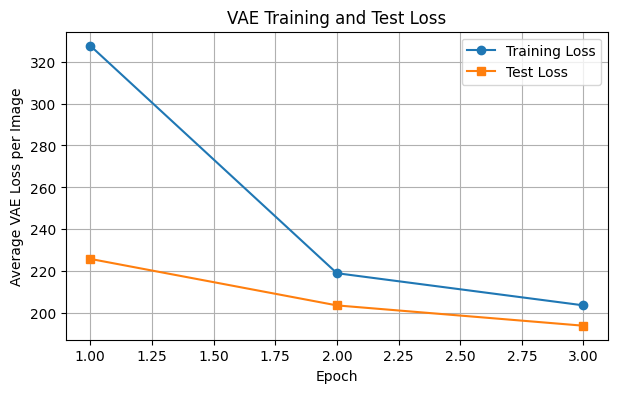

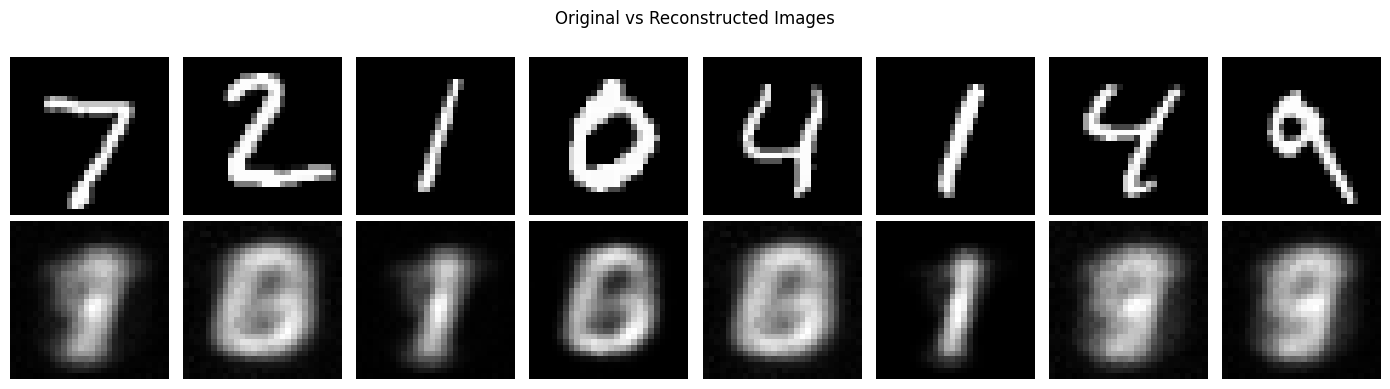

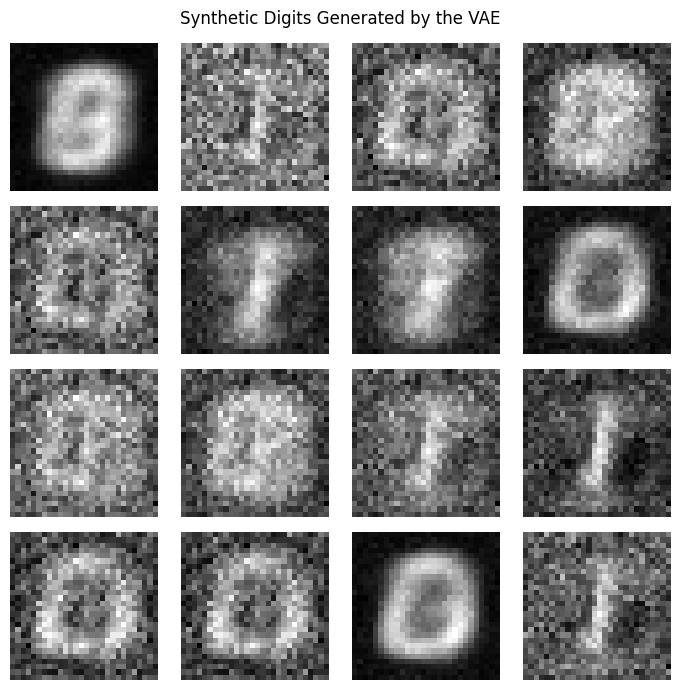

In [ ]:
# -*- coding: utf-8 -*-
"""Untitled11.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/11-AXfHCHK7owRyHK23Vvu1nfKPHcUEUm

# ***Step 1 — Import Libraries and Load the Dataset***
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# Reproducibility
torch.manual_seed(42)

# CPU or GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# Convert images to tensors with pixel values in [0, 1]
transform = transforms.ToTensor()

train_full = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_full = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Use smaller subsets for a 3-hour class
generator = torch.Generator().manual_seed(42)

train_indices = torch.randperm(
    len(train_full), generator=generator
)[:6000].tolist()

test_indices = list(range(1000))

train_dataset = Subset(train_full, train_indices)
test_dataset = Subset(test_full, test_indices)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

images, labels = next(iter(train_loader))

print("Batch shape:", images.shape)

# Show examples
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0], cmap="gray")
    ax.set_title(f"Digit: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

"""# **Step 2 — Define the VAE Architecture**"""

class VAE(nn.Module):

    def __init__(self, latent_dim=2):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU()
        )

        # Two outputs for the latent distribution
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        z = mu + std * epsilon
        return z

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        x = x.view(-1, 784)

        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)

        reconstruction = self.decode(z)

        return reconstruction, mu, logvar


model = VAE(latent_dim=2).to(device)

print(model)

"""# ***Step 3 — Define the Loss Function***"""

def vae_loss(reconstruction, x, mu, logvar):

    x = x.view(-1, 784)

    # Sum BCE over all pixels in the batch
    reconstruction_loss = F.binary_cross_entropy(
        reconstruction,
        x,
        reduction="sum"
    )

    # KL divergence from standard normal
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    # Divide by batch size for per-image loss
    batch_size = x.size(0)

    total_loss = (
        reconstruction_loss + kl_loss
    ) / batch_size

    return total_loss, reconstruction_loss / batch_size, kl_loss / batch_size

"""# ***Step 4 — Train the VAE***"""

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 3

train_history = []
test_history = []

for epoch in range(epochs):

    # Training
    model.train()

    train_total = 0.0
    train_reconstruction = 0.0
    train_kl = 0.0

    for images, _ in train_loader:

        images = images.to(device)

        optimizer.zero_grad()

        reconstructed, mu, logvar = model(images)

        loss, recon_loss, kl_loss = vae_loss(
            reconstructed, images, mu, logvar
        )

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        train_total += loss.item() * batch_size
        train_reconstruction += (
            recon_loss.item() * batch_size
        )
        train_kl += kl_loss.item() * batch_size

    train_avg = train_total / len(train_dataset)
    train_history.append(train_avg)

    # Held-out reconstruction evaluation
    model.eval()
    test_total = 0.0

    with torch.no_grad():
        for images, _ in test_loader:

            images = images.to(device)

            reconstructed, mu, logvar = model(images)

            loss, _, _ = vae_loss(
                reconstructed, images, mu, logvar
            )

            test_total += loss.item() * images.size(0)

    test_avg = test_total / len(test_dataset)
    test_history.append(test_avg)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_avg:.2f} | "
        f"Recon Loss: "
        f"{train_reconstruction/len(train_dataset):.2f} | "
        f"KL Loss: "
        f"{train_kl/len(train_dataset):.2f} | "
        f"Test Loss: {test_avg:.2f}"
    )

"""# ***Step 5 — Plot the Training Curve***"""

plt.figure(figsize=(7, 4))

plt.plot(
    range(1, epochs + 1),
    train_history,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, epochs + 1),
    test_history,
    marker="s",
    label="Test Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Average VAE Loss per Image")
plt.title("VAE Training and Test Loss")
plt.legend()
plt.grid(True)
plt.show()

"""# ***Step 6 — Reconstruct Test Images***"""

model.eval()

images, labels = next(iter(test_loader))
images = images[:8].to(device)

with torch.no_grad():
    reconstructed, _, _ = model(images)

original = images.cpu().view(-1, 28, 28)
reconstructed = reconstructed.cpu().view(-1, 28, 28)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))

for i in range(8):

    axes[0, i].imshow(original[i], cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i], cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Reconstructed", fontsize=12)

plt.suptitle("Original vs Reconstructed Images")
plt.tight_layout()
plt.show()

"""# ***Step 7 — Generate Completely New Digits***"""

model.eval()

with torch.no_grad():

    # Sample 16 new latent vectors
    z = torch.randn(16, 2).to(device)

    # Generate images using the decoder
    generated = model.decode(z)

    generated = generated.cpu().view(-1, 28, 28)

fig, axes = plt.subplots(4, 4, figsize=(7, 7))

for i, ax in enumerate(axes.flat):

    ax.imshow(generated[i], cmap="gray")
    ax.axis("off")

plt.suptitle("Synthetic Digits Generated by the VAE")
plt.tight_layout()
plt.show()

Device: cpu
Training images: 30000
Testing images: 1000
Batch shape: torch.Size([128, 1, 28, 28])


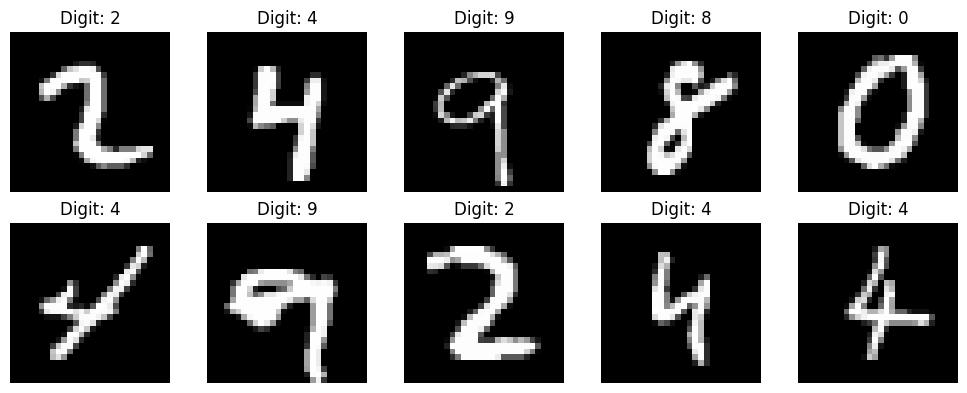

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=16, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Epoch 1/5 | Train Loss: 201.37 | Recon Loss: 188.71 | KL Loss: 12.66 | Test Loss: 152.79
Epoch 2/5 | Train Loss: 142.49 | Recon Loss: 125.36 | KL Loss: 17.12 | Test Loss: 131.39
Epoch 3/5 | Train Loss: 128.16 | Recon Loss: 108.29 | KL Loss: 19.86 | Test Loss: 123.23
Epoch 4/5 | Train Loss: 122.18 | Recon Loss: 101.32 | KL Loss: 20.86 | Test Loss: 118.87
Epoch 5/5 | Train Loss: 118.91 | Recon Loss: 97.56 | KL Loss: 21.35 | Test Loss: 116.53


In [ ]:
# -*- coding: utf-8 +-*-
"""Untitled11.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/11-AXfHCHK7owRyHK23Vvu1nfKPHcUEUm

# ***Step 1 — Import Libraries and Load the Dataset***
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# Reproducibility
torch.manual_seed(42)

# CPU or GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# Convert images to tensors with pixel values in [0, 1]
transform = transforms.ToTensor()

train_full = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_full = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Increase subset size to 30,000 images for a much clearer output quality
generator = torch.Generator().manual_seed(42)

train_indices = torch.randperm(
    len(train_full), generator=generator
)[:30000].tolist()

test_indices = list(range(1000))

train_dataset = Subset(train_full, train_indices)
test_dataset = Subset(test_full, test_indices)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

images, labels = next(iter(train_loader))

print("Batch shape:", images.shape)

# Show examples
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0], cmap="gray")
    ax.set_title(f"Digit: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

"""# **Step 2 — Define the VAE Architecture (Improved)**"""

class VAE(nn.Module):

    def __init__(self, latent_dim=16):
        super().__init__()

        # Enhanced capacity with 256 hidden units
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU()
        )

        # Latent distribution parameters
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        z = mu + std * epsilon
        return z

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        x = x.view(-1, 784)

        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)

        reconstruction = self.decode(z)

        return reconstruction, mu, logvar


# Increase latent dim to 16 for significantly higher-quality reconstructions
model = VAE(latent_dim=16).to(device)

print(model)

"""# ***Step 3 — Define the Loss Function***"""

def vae_loss(reconstruction, x, mu, logvar):

    x = x.view(-1, 784)

    # Sum BCE over all pixels in the batch
    reconstruction_loss = F.binary_cross_entropy(
        reconstruction,
        x,
        reduction="sum"
    )

    # KL divergence from standard normal
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    # Divide by batch size for per-image loss
    batch_size = x.size(0)

    total_loss = (
        reconstruction_loss + kl_loss
    ) / batch_size

    return total_loss, reconstruction_loss / batch_size, kl_loss / batch_size

"""# ***Step 4 — Train the VAE (More Epochs)***"""

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 5

train_history = []
test_history = []

for epoch in range(epochs):

    # Training
    model.train()

    train_total = 0.0
    train_reconstruction = 0.0
    train_kl = 0.0

    for images, _ in train_loader:

        images = images.to(device)

        optimizer.zero_grad()

        reconstructed, mu, logvar = model(images)

        loss, recon_loss, kl_loss = vae_loss(
            reconstructed, images, mu, logvar
        )

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        train_total += loss.item() * batch_size
        train_reconstruction += (
            recon_loss.item() * batch_size
        )
        train_kl += kl_loss.item() * batch_size

    train_avg = train_total / len(train_dataset)
    train_history.append(train_avg)

    # Held-out reconstruction evaluation
    model.eval()
    test_total = 0.0

    with torch.no_grad():
        for images, _ in test_loader:

            images = images.to(device)

            reconstructed, mu, logvar = model(images)

            loss, _, _ = vae_loss(
                reconstructed, images, mu, logvar
            )

            test_total += loss.item() * images.size(0)

    test_avg = test_total / len(test_dataset)
    test_history.append(test_avg)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_avg:.2f} | "
        f"Recon Loss: "
        f"{train_reconstruction/len(train_dataset):.2f} | "
        f"KL Loss: "
        f"{train_kl/len(train_dataset):.2f} | "
        f"Test Loss: {test_avg:.2f}"
    )

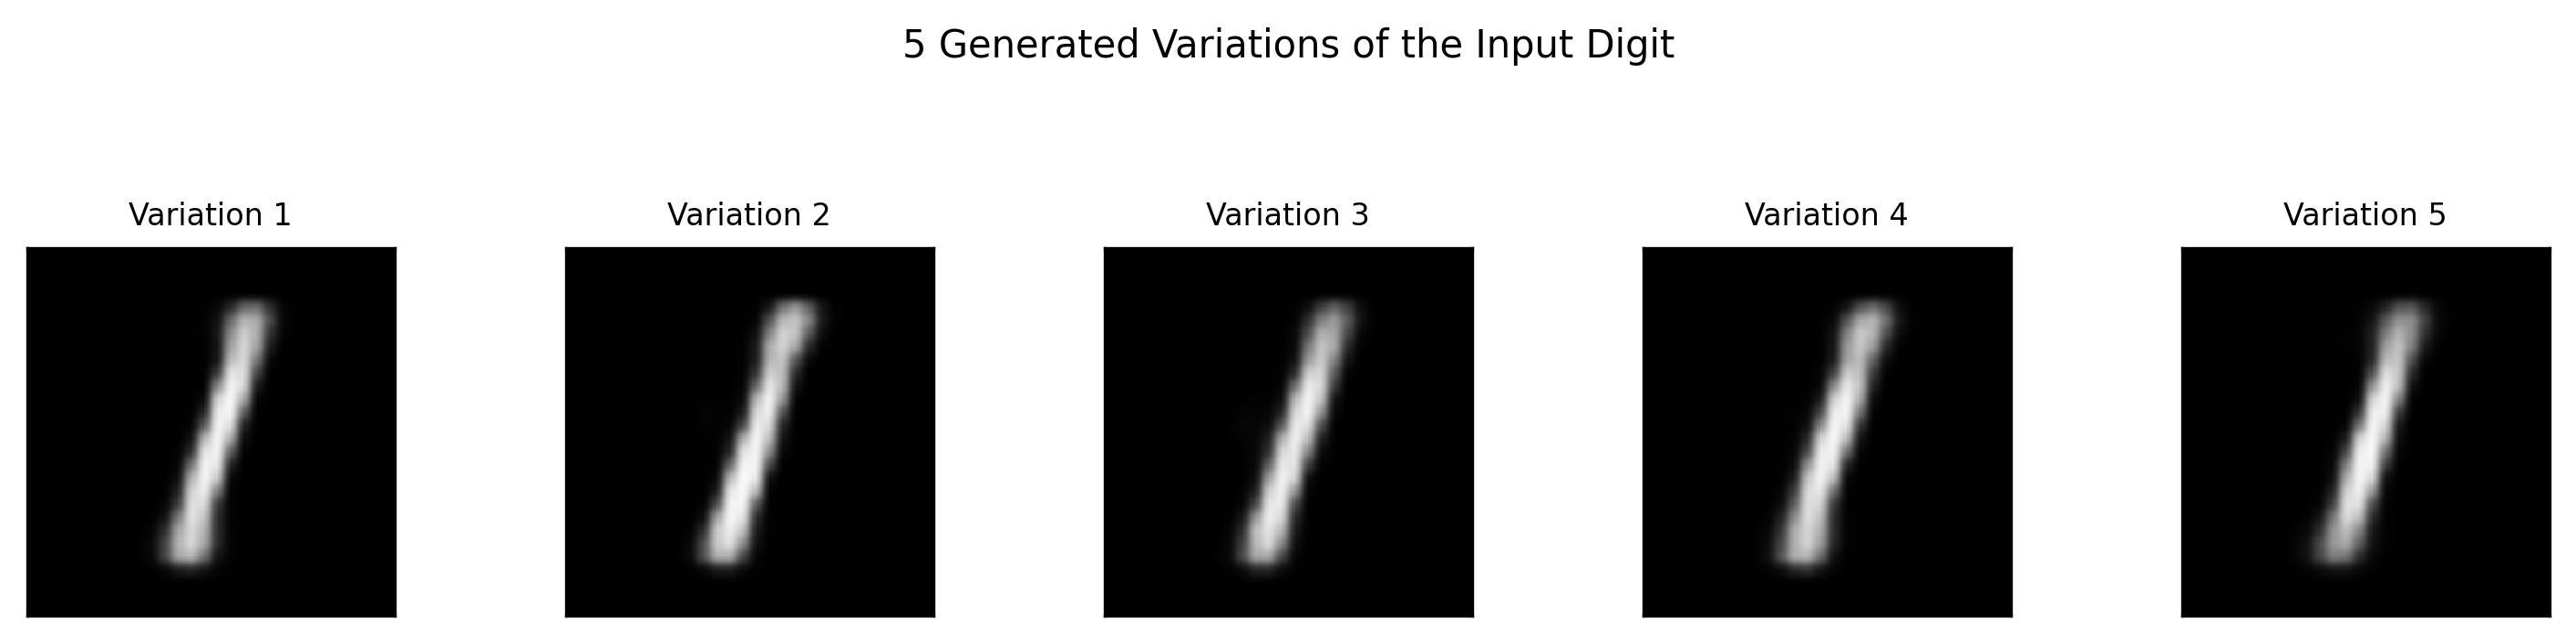

In [ ]:
model.eval()

# Find an actual digit from the test dataset
source_digit = None
for image, label in test_dataset:
    if label == 1:  # Choose digit 1
        source_digit = image.view(1, -1).to(device)
        break

if source_digit is None:
    raise ValueError("Specified digit class not found in dataset.")

latent_dim = model.fc_mu.out_features

with torch.no_grad():
    mu, logvar = model.encode(source_digit)
    # Sample variations around the encoded latent representation of the source image
    noise = torch.randn(5, latent_dim, device=device)
    z = mu + 0.5 * torch.exp(0.5 * logvar) * noise
    variations = model.decode(z).cpu().view(5, 28, 28)

# Display 5 variations of the source image with enhanced smoothing
fig, axes = plt.subplots(1, 5, figsize=(10, 2), dpi=300)
for i in range(5):
    axes[i].imshow(
        variations[i].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="hamming"
    )
    axes[i].set_xticks([])
    axes[i].set_yticks([])
    axes[i].set_title(f"Variation {i+1}", fontsize=8)

plt.suptitle("5 Generated Variations of the Input Digit", fontsize=10, y=1.15)
plt.tight_layout()
plt.show()